# 02_9. Confusion matrices of the stage-2 models / Матрицы ошибок моделей этапа 2

**EN.** AUC (used so far) measures how well a model *orders* loans by risk, without a cut-off. A **confusion matrix** shows what the model predicts at a cut-off:

|  | predicted default | predicted no default |
| --- | --- | --- |
| **default within 12 months** | true positive, TP | false negative, FN (missed default) |
| **no default** | false positive, FP (false alarm) | true negative, TN |

**Threshold 0.5:** a loan is predicted to default when its predicted PD is at least 0.5. From the matrix: **accuracy** = (TP + TN) / all — the share of all loans classified correctly; **precision** = TP / (TP + FP) — the share of predicted defaults that are real; **recall** = TP / (TP + FN) — the share of real defaults that the model finds; **F1** = 2 · precision · recall / (precision + recall) — one number that balances the two; **balanced accuracy** = (recall + TN / (TN + FP)) / 2 — the average of the share of defaults found and the share of non-defaults recognised, so the 99.8 % majority cannot inflate it (always answering "no default" gives 0.5). Next to them two threshold-free metrics: **AUC** and **PR-AUC** (area under the precision–recall curve, average precision; a random ranking gives the event rate, 0.0020).

Same validation as in stage 2 (2016-06 … 2017-03, without the hurricane rows; task Y1, loans current at t, DPD = 0, never in default before t), same models: CatBoost (02_5), logistic regression on WoE, XGBoost, LightGBM and random forest (02_8), each on the 18 selected features and on all 59. Nothing is refitted: the notebook reads the cached validation predictions. The predicted PDs are the raw outputs of untuned stage-2 models trained with weights 1/r, i.e. on the population scale, not yet calibrated (calibration is stage 3). Observations are loan × quarter-end dates.

**RU.** AUC, на который мы смотрели до сих пор, показывает, насколько хорошо модель *упорядочивает* кредиты по риску, без порога. **Матрица ошибок** показывает, что модель предсказывает при пороге:

|  | предсказан дефолт | предсказано «без дефолта» |
| --- | --- | --- |
| **дефолт в течение 12 месяцев** | верное срабатывание, TP | пропуск, FN (дефолт не замечен) |
| **дефолта нет** | ложная тревога, FP | верное «без дефолта», TN |

**Порог 0,5:** дефолт предсказывается, если прогнозная PD не меньше 0,5. Из матрицы: **доля верных ответов** (accuracy) = (TP + TN) / все — доля всех кредитов, по которым модель ответила верно; **точность** (precision) = TP / (TP + FP) — доля предсказанных дефолтов, которые настоящие; **полнота** (recall) = TP / (TP + FN) — доля настоящих дефолтов, которые нашла модель; **F1** = 2 · точность · полнота / (точность + полнота) — одно число, уравновешивающее обе; **сбалансированная доля верных ответов** (balanced accuracy) = (полнота + TN / (TN + FP)) / 2 — среднее из доли найденных дефолтов и доли верно названных «без дефолта», поэтому 99,8 % большинства её не завышают (ответ «дефолта не будет» для всех даёт 0,5). Рядом две метрики без порога: **AUC** и **PR-AUC** (площадь под кривой точность–полнота, average precision; случайный порядок даёт долю событий, 0,0020).

Та же validation, что на этапе 2 (2016-06 … 2017-03, без наблюдений урагана; задача Y1, кредиты без просрочки на t, DPD = 0, не бывшие в дефолте до t), те же модели: CatBoost (02_5), логистическая регрессия на WoE, XGBoost, LightGBM и случайный лес (02_8), каждая на 18 отобранных признаках и на всех 59. Ничего не переобучается: ноутбук читает сохранённые прогнозы на validation. Прогнозные PD — сырые выходы моделей этапа 2 без подбора, обученных с весами 1/r, то есть в масштабе популяции, ещё без калибровки (калибровка — этап 3). Наблюдение — кредит на дату конца квартала.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

from xai_ews.config import feature_config
from xai_ews.data.features import candidate_features
from xai_ews.features import importance, other_models
from xai_ews.features.data import TASKS
from xai_ews.features.evaluation import confusion_at_threshold
from sklearn.metrics import average_precision_score
from xai_ews.features.univariate import weighted_auc
from xai_ews.paths import FEATURE_SELECTION_DIR

CFG = feature_config()
SEED = CFG["data"]["seed"]
P_CB, P_OTHER = CFG["rules"]["importance"]["catboost"], CFG["rules"]["other_models"]
ROWS = {**{k: None for k in other_models.KINDS}, "random_forest": P_OTHER["random_forest_train_rows"]}
red = pd.read_csv(FEATURE_SELECTION_DIR / "redundancy.csv")
CAND = red.loc[red["pass_redundancy"], "feature"].tolist()
FINAL, ALL = CFG["selected"]["features"], candidate_features()
SEL = "candidates" if FINAL == CAND else "selected"   # cache name of the selected-set models in 02_6 / 02_8
THRESHOLD = 0.5
LEARNERS = ["catboost", *other_models.KINDS]

def prediction_path(learner, task, name, feats):
    if learner == "catboost":
        return importance.cache_paths(task, feats, P_CB, f"m_{name}", SEED)[0]
    return other_models.cache_paths(learner, task, feats, P_OTHER, f"{learner}_{name}", SEED, ROWS[learner])[0]

preds = {}
for task in TASKS:
    for learner in LEARNERS:
        for name, feats in [(SEL, FINAL), ("all", ALL)]:
            preds[(task, learner, name)] = pl.read_parquet(prediction_path(learner, task, name, feats)).filter(
                ~pl.col("val_hurricane_2017"))
p0 = next(iter(preds.values()))
print(f"validation without hurricane rows: {p0.height:,} observations, {int(p0[task].sum()):,} events ({p0[task].mean():.2%})")

validation without hurricane rows: 1,854,380 observations, 3,706 events (0.20%)


### 1. Confusion matrices and metrics / Матрицы ошибок и метрики

**EN.** One row per model and feature set: `selected` — the 18 selected features, `all` — all 59 candidates.

**RU.** Одна строка на модель и набор признаков: `selected` — 18 отобранных признаков, `all` — все 59 кандидатов.

In [2]:
rows = []
for (task, learner, name), p in preds.items():
    rows.append({"task": task, "model": learner, "features": "selected" if name == SEL else name,
                 "auc": weighted_auc(p[task].to_numpy(), p["logit"].to_numpy()),
                 "pr_auc": average_precision_score(p[task].to_numpy(), p["logit"].to_numpy()),
                 **confusion_at_threshold(p, task, THRESHOLD)})
cm = pd.DataFrame(rows)
cm.to_csv(FEATURE_SELECTION_DIR / "confusion_matrices.csv", index=False)
cm.set_index(["features", "model"]).sort_index(ascending=[False, True])[["tp", "fp", "fn", "tn", "auc", "pr_auc", "accuracy", "balanced_accuracy", "precision", "recall", "f1"]]

tp  fp    fn       tn    auc  pr_auc  accuracy  balanced_accuracy  precision  recall     f1
features model                                                                                                     
selected catboost        0   1  3706  1850673 0.8538  0.0147    0.9980             0.5000     0.0000  0.0000 0.0000
         lightgbm        0   0  3706  1850674 0.8548  0.0153    0.9980             0.5000     0.0000  0.0000 0.0000
         logistic_woe    0   0  3706  1850674 0.8417  0.0112    0.9980             0.5000     0.0000  0.0000 0.0000
         random_forest   0   0  3706  1850674 0.8392  0.0139    0.9980             0.5000     0.0000  0.0000 0.0000
         xgboost         0   0  3706  1850674 0.8552  0.0156    0.9980             0.5000     0.0000  0.0000 0.0000
all      catboost        0   1  3706  1850673 0.8509  0.0132    0.9980             0.5000     0.0000  0.0000 0.0000
         lightgbm        0   0  3706  1850674 0.8326  0.0120    0.9980             0.5000     0.0000  0.0000 0.0000
         logistic_woe    0   0  3706  1850674 0.8471  0.0123    0.9980             0.5000     0.0000  0.0000 0.0000
         random_forest   0   0  3706  1850674 0.8336  0.0128    0.9980             0.5000     0.0000  0.0000 0.0000
         xgboost         0   0  3706  1850674 0.8561  0.0164    0.9980             0.5000     0.0000  0.0000 0.0000

**EN. How to read.** Validation has 1,854,380 observations and 3,706 defaults (0.20 %).
- **At PD ≥ 0.5 the models raise no alerts at all.** On the 18 selected features and on all 59 CatBoost raises one alert (a false one), the logistic regression, XGBoost, LightGBM and the random forest none.
- **Why.** For loans that are current at t and have never been in default the models are almost never confident of a default within 12 months: almost all predicted PDs are below a few per cent. Even at PD ≥ 0.1 (section 2) CatBoost flags only 62 observations, LightGBM 17, XGBoost 4, and the logistic regression and the random forest none — these two have no PD at or above 0.05.
- **Accuracy 0.9980** for every model — exactly the share of non-defaults: with no alerts a model answers "no default" for everyone. **Balanced accuracy 0.500**, the value of always answering "no default".
- **Precision, recall and F1 at 0.5 are all 0**: there is not a single true alert (precision is undefined and shown as 0).
- **AUC 0.839–0.855** and **PR-AUC 0.011–0.016** on the 18 features (AUC 0.833–0.856, PR-AUC 0.012–0.016 on all 59) do not depend on the threshold. PR-AUC is 6–8 times the 0.0020 of a random ranking.

**Why AUC is fairly high while precision is low, and why PR-AUC and balanced accuracy are added.** AUC is the probability that a random default gets a higher score than a random non-default; it compares the rate of found defaults (recall) with the rate of false alarms *among non-defaults* (FPR) and therefore does not depend on how rare defaults are. The models do separate the classes: at the threshold 0.005 CatBoost finds 51 % of the defaults (1,898 of 3,706) while raising a false alarm for only 8.6 % of the non-defaults. But non-defaults are about 500 times more numerous, so these 8.6 % are 158,480 false alarms against 1,898 true ones, and precision is 0.012: precision = recall · π / (recall · π + FPR · (1 − π)) with the event rate π = 0.0020. A good AUC together with a low precision is therefore expected for a rare event — the denominator of the false-alarm rate is all normal loans, the denominator of precision is the alert list. To show the quality *on the class we are looking for* two more metrics are reported: **PR-AUC** — the precision–recall analogue of AUC, which does depend on the event rate (random ranking = 0.0020; our models 0.011–0.016), and **balanced accuracy**, which, unlike accuracy, cannot be inflated by correctly classified non-defaults.
- **18 vs 59 features:** at 0.5 the matrices are the same (CatBoost has one false alert with either set). By PR-AUC the selected 18 are better for CatBoost (0.0147 vs 0.0132), LightGBM (0.0153 vs 0.0120) and the random forest (0.0139 vs 0.0128), and all 59 slightly better for XGBoost (0.0164 vs 0.0156) and the logistic regression (0.0123 vs 0.0112); the AUC comparison with confidence intervals is in 02_8.

**RU. Как читать.** В validation 1 854 380 наблюдений и 3 706 дефолтов (0,20 %).
- **При PD ≥ 0,5 модели вообще не поднимают тревог.** И на 18 отобранных признаках, и на всех 59 CatBoost даёт одну тревогу (ложную), логистическая регрессия, XGBoost, LightGBM и случайный лес — ни одной.
- **Почему.** Для кредитов без просрочки на t, ни разу не бывших в дефолте, модели почти никогда не уверены, что дефолт случится в ближайшие 12 месяцев: почти все прогнозные PD меньше нескольких процентов. Даже при PD ≥ 0,1 (раздел 2) CatBoost отмечает лишь 62 наблюдения, LightGBM — 17, XGBoost — 4, а логистическая регрессия и случайный лес — ни одного: у этих двух нет PD не меньше 0,05.
- **Accuracy 0,9980** у всех моделей — ровно доля не-дефолтов: без тревог модель отвечает «дефолта не будет» для всех. **Balanced accuracy 0,500** — значение ответа «дефолта не будет» для всех.
- **Точность, полнота и F1 при 0,5 равны 0**: нет ни одной настоящей тревоги (точность не определена и показана как 0).
- **AUC 0,839–0,855** и **PR-AUC 0,011–0,016** на 18 признаках (AUC 0,833–0,856, PR-AUC 0,012–0,016 на всех 59) от порога не зависят. PR-AUC в 6–8 раз больше 0,0020 у случайного порядка.

**Почему AUC довольно высокий, а точность низкая, и зачем добавлены PR-AUC и balanced accuracy.** AUC — вероятность того, что случайный дефолт получит более высокий прогноз, чем случайный не-дефолт; он сравнивает долю найденных дефолтов (полноту) с долей ложных тревог *среди не-дефолтов* (FPR) и поэтому не зависит от того, насколько дефолты редки. Модели классы действительно разделяют: при пороге 0,005 CatBoost находит 51 % дефолтов (1 898 из 3 706) и ложно тревожит лишь 8,6 % не-дефолтов. Но не-дефолтов примерно в 500 раз больше, поэтому эти 8,6 % — 158 480 ложных тревог против 1 898 настоящих, и точность 0,012: точность = полнота · π / (полнота · π + FPR · (1 − π)), где π = 0,0020 — доля событий. Хороший AUC вместе с низкой точностью для редкого события поэтому ожидаем: у доли ложных тревог в знаменателе все нормальные кредиты, у точности — список тревог. Чтобы показать качество *на том классе, который мы ищем*, приводятся ещё две метрики: **PR-AUC** — аналог AUC по кривой точность–полнота, который зависит от доли событий (случайный порядок = 0,0020; наши модели 0,011–0,016), и **balanced accuracy**, которую, в отличие от accuracy, нельзя завысить верно названными не-дефолтами.
- **18 против 59 признаков:** при 0,5 матрицы одинаковы (у CatBoost одна ложная тревога на обоих наборах). По PR-AUC отобранные 18 лучше у CatBoost (0,0147 против 0,0132), LightGBM (0,0153 против 0,0120) и случайного леса (0,0139 против 0,0128), а все 59 чуть лучше у XGBoost (0,0164 против 0,0156) и логистической регрессии (0,0123 против 0,0112); сравнение AUC с доверительными интервалами — в 02_8.

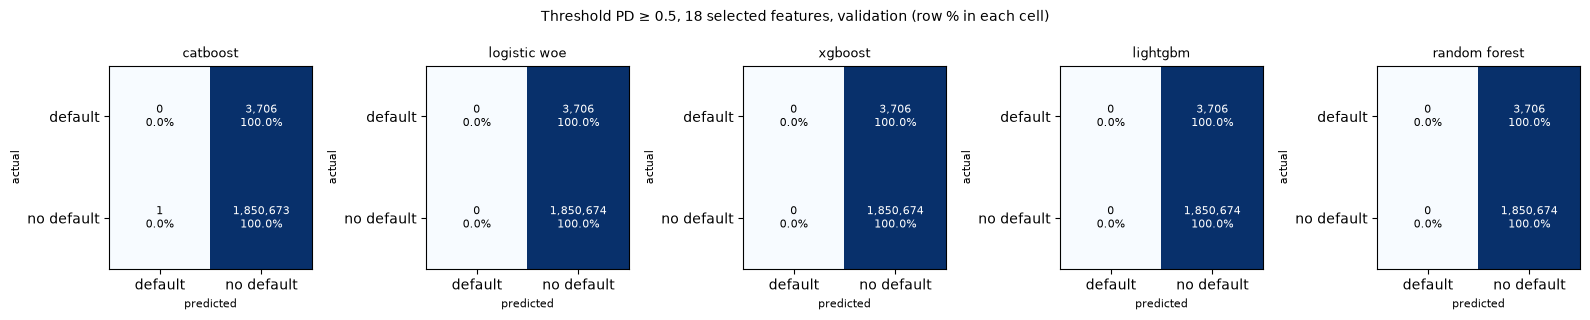

In [3]:
fig, axes = plt.subplots(1, len(LEARNERS), figsize=(3.2 * len(LEARNERS), 3.2))
for ax, learner in zip(axes, LEARNERS):
    r = cm.query("model == @learner and features == 'selected'").iloc[0]
    m = np.array([[r.tp, r.fn], [r.fp, r.tn]])
    ax.imshow(m / m.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, f"{v:,}\n{v / m[i].sum():.1%}", ha="center", va="center", fontsize=8,
                color="white" if v / m[i].sum() > 0.5 else "black")
    ax.set_xticks([0, 1], ["default", "no default"]); ax.set_yticks([0, 1], ["default", "no default"])
    ax.set_xlabel("predicted", fontsize=8); ax.set_ylabel("actual", fontsize=8)
    ax.set_title(learner.replace("_", " "), fontsize=9); ax.grid(False)
fig.suptitle(f"Threshold PD ≥ 0.5, {len(FINAL)} selected features, validation (row % in each cell)", fontsize=10)
plt.tight_layout(); plt.show()

### 2. Lower thresholds: from 0.5 down to 0.005 / Более низкие пороги: от 0,5 до 0,005

**EN.** Since at 0.5 the models raise no alerts, the same matrices are computed at 0.3, 0.2, 0.1, 0.05, 0.02, 0.01 and 0.005 for every model on the 18 selected features (the plots use a log x-axis). A lower threshold puts more loans on the list: recall rises, precision falls. This is a preview on validation with untuned, uncalibrated stage-2 models; the alert rule itself (calibrated PD ≥ 0.01, sensitivity 0.02 and 0.005, `configs/data.yaml`) is applied in stage 3, before test is looked at.

**RU.** Поскольку при 0,5 модели не поднимают тревог, те же матрицы считаются при 0,3, 0,2, 0,1, 0,05, 0,02, 0,01 и 0,005 для каждой модели на 18 отобранных признаках (на графиках ось x логарифмическая). Чем ниже порог, тем больше кредитов в списке: полнота растёт, точность падает. Это предварительный взгляд на validation по моделям этапа 2 без подбора и калибровки; само правило тревоги (калиброванная PD ≥ 0,01, чувствительность 0,02 и 0,005, `configs/data.yaml`) применяется на этапе 3, до просмотра test.

In [4]:
THRESHOLDS = (0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005)
sweep = pd.DataFrame([{"model": learner, "auc": weighted_auc(p[task].to_numpy(), p["logit"].to_numpy()),
                       **confusion_at_threshold(p, task, thr)}
                      for (task, learner, name), p in preds.items() if name == SEL for thr in THRESHOLDS])
sweep["alerts"] = sweep["tp"] + sweep["fp"]
sweep.to_csv(FEATURE_SELECTION_DIR / "threshold_sweep.csv", index=False)
sweep.pivot(index="model", columns="threshold", values=["accuracy", "balanced_accuracy", "precision", "recall", "f1"]).sort_index(axis=1, level=0, sort_remaining=False).round(3)

accuracy                                                  balanced_accuracy                                            ... precision                                           recall  \
threshold       0.0050 0.0100 0.0200 0.0500 0.1000 0.2000 0.3000 0.5000            0.0050 0.0100 0.0200 0.0500 0.1000 0.2000 0.3000  ...    0.0100 0.0200 0.0500 0.1000 0.2000 0.3000 0.5000 0.0050   
model                                                                                                                                ...                                                              
catboost        0.9140 0.9720 0.9930 0.9980 0.9980 0.9980 0.9980 0.9980            0.7130 0.6160 0.5360 0.5030 0.5000 0.5000 0.5000  ...    0.0190 0.0300 0.0420 0.0480 0.0000 0.0000 0.0000 0.5120   
lightgbm        0.9150 0.9700 0.9920 0.9980 0.9980 0.9980 0.9980 0.9980            0.7170 0.6240 0.5480 0.5060 0.5000 0.5000 0.5000  ...    0.0190 0.0310 0.0480 0.0590 0.0000 0.0000 0.0000 0.5180   
logistic_woe    0.9180 0.9820 0.9980 0.9980 0.9980 0.9980 0.9980 0.9980            0.6860 0.5640 0.5010 0.5000 0.5000 0.5000 0.5000  ...    0.0170 0.0250 0.0000 0.0000 0.0000 0.0000 0.0000 0.4530   
random_forest   0.9040 0.9730 0.9960 0.9980 0.9980 0.9980 0.9980 0.9980            0.7110 0.6090 0.5160 0.5000 0.5000 0.5000 0.5000  ...    0.0190 0.0360 0.0000 0.0000 0.0000 0.0000 0.0000 0.5180   
xgboost         0.9140 0.9680 0.9920 0.9980 0.9980 0.9980 0.9980 0.9980            0.7140 0.6330 0.5480 0.5030 0.5000 0.5000 0.5000  ...    0.0190 0.0300 0.0430 0.0000 0.0000 0.0000 0.0000 0.5140   

                                                                
threshold     0.0100 0.0200 0.0500 0.1000 0.2000 0.3000 0.5000  
model                                                           
catboost      0.2580 0.0770 0.0060 0.0010 0.0000 0.0000 0.0000  
lightgbm      0.2780 0.1030 0.0120 0.0000 0.0000 0.0000 0.0000  
logistic_woe  0.1450 0.0020 0.0000 0.0000 0.0000 0.0000 0.0000  
random_forest 0.2430 0.0340 0.0000 0.0000 0.0000 0.0000 0.0000  
xgboost       0.2960 0.1030 0.0070 0.0000 0.0000 0.0000 0.0000  

[5 rows x 40 columns]

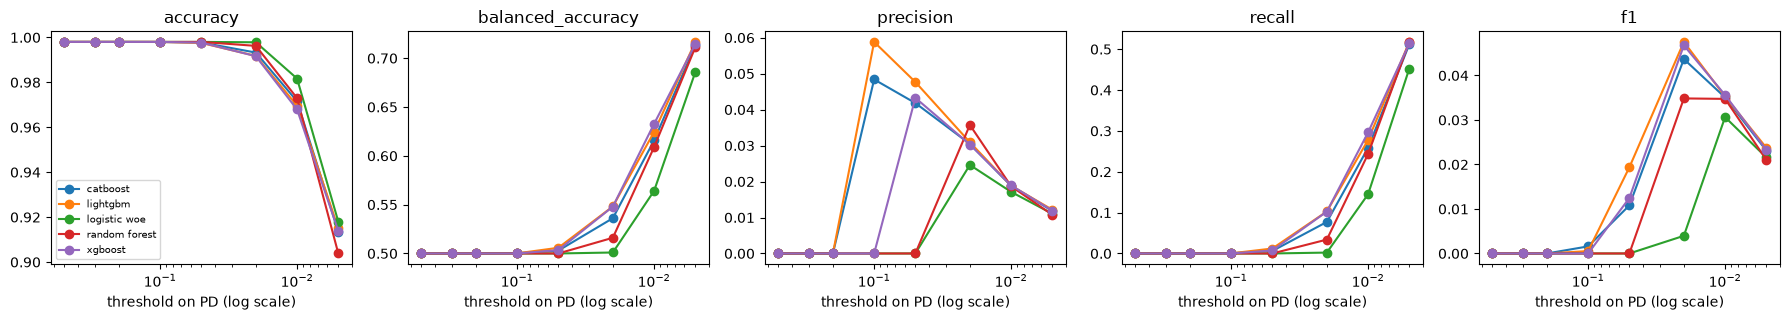

,alerts,tp,fp,fn,accuracy,balanced_accuracy,precision,recall,f1
threshold,,,,,,,,,
0.5000,1,0,1,3706,0.9980,0.5000,0.0000,0.0000,0.0000
0.3000,5,0,5,3706,0.9980,0.5000,0.0000,0.0000,0.0000
0.2000,12,0,12,3706,0.9980,0.5000,0.0000,0.0000,0.0000
0.1000,62,3,59,3703,0.9980,0.5004,0.0484,0.0008,0.0016
0.0500,550,23,527,3683,0.9977,0.5030,0.0418,0.0062,0.0108
0.0200,9387,286,9101,3420,0.9932,0.5361,0.0305,0.0772,0.0437
0.0100,50933,958,49975,2748,0.9716,0.6157,0.0188,0.2585,0.0351
0.0050,160378,1898,158480,1808,0.9136,0.7133,0.0118,0.5121,0.0231


In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.3), sharex=True)
for ax, metric in zip(axes, ["accuracy", "balanced_accuracy", "precision", "recall", "f1"]):
    for learner, g in sweep.groupby("model"):
        ax.plot(g["threshold"], g[metric], marker="o", label=learner.replace("_", " "))
    ax.set_title(metric); ax.set_xlabel("threshold on PD (log scale)"); ax.set_xscale("log"); ax.invert_xaxis()
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
sweep.query("model == 'catboost'").set_index("threshold")[["alerts", "tp", "fp", "fn", "accuracy", "balanced_accuracy", "precision", "recall", "f1"]]

**EN. How to read.** The table under the plots is CatBoost; all models are in `threshold_sweep.csv`.
- **The list stays tiny down to 0.05** and grows only below that, because almost all PDs are below a few per cent: CatBoost 1 alert at 0.5, 62 at 0.1, 550 at 0.05, 9,387 at 0.02 (0.5 % of the observations), 50,933 at 0.01 (2.7 %), 160,378 at 0.005 (8.6 %).
- **Recall** (CatBoost): 0 at 0.5, 0.1 % at 0.1, 0.6 % at 0.05, 8 % at 0.02, **26 % at 0.01**, **51 % at 0.005**. All models: 0.2–10 % at 0.02, 14–30 % at 0.01, 45–52 % at 0.005.
- **Precision** (CatBoost): no true alert at 0.2 and above, 4.8 % at 0.1 (only 62 alerts), 3.1 % at 0.02, **1.9 % at 0.01** and 1.2 % at 0.005. At 0.01 that is 9.4 times the 0.20 % event rate; even at 0.005 it is 5.9 times.
- **Balanced accuracy** rises as the threshold is lowered: 0.50 at 0.5, 0.50–0.55 at 0.02, 0.56–0.63 at 0.01, **0.69–0.72 at 0.005**. **Accuracy** falls from 0.9980 to 0.90–0.92 at 0.005 — below the 0.9980 of always answering "no default", although half of the defaults are then found. This is why accuracy is not used to choose the threshold.
- **F1 stays low for every model**: at most 0.03–0.05, reached at 0.01–0.02. With 0.20 % events among loans that pay on time, no threshold gives both a high precision and a high recall.
- The models differ most at high thresholds because their PD scales differ (the logistic regression and the random forest have no PD at or above 0.05; at 0.1 XGBoost flags 4 observations, LightGBM 17, CatBoost 62). At 0.01 and 0.005 they come close: recall 0.45–0.52 and precision 1.1–1.2 % at 0.005; at 0.01 the logistic regression lags (recall 0.14 against 0.24–0.30).

So PD ≥ 0.5 gives no watch list at all for this population; a usable list lies at roughly 0.005–0.02. Which one depends on how many loans the bank can review: about 0.5 % of the portfolio to catch 8 % of the defaults (0.02), 2.7 % to catch 26 % (0.01), or about 8.6 % to catch half (0.005) (CatBoost). The alert rule of the thesis is set in `configs/data.yaml` (`alert.pd_threshold`): **calibrated PD ≥ 0.01**, with 0.02 and 0.005 as sensitivity. The numbers here are for uncalibrated, untuned stage-2 models; the rule is applied in stage 3 to the tuned, calibrated model, before test.

**RU. Как читать.** Таблица под графиками — CatBoost; все модели — в `threshold_sweep.csv`.
- **Список остаётся крошечным до 0,05** и растёт только ниже, потому что почти все PD меньше нескольких процентов: CatBoost — 1 тревога при 0,5, 62 при 0,1, 550 при 0,05, 9 387 при 0,02 (0,5 % наблюдений), 50 933 при 0,01 (2,7 %), 160 378 при 0,005 (8,6 %).
- **Полнота** (CatBoost): 0 при 0,5, 0,1 % при 0,1, 0,6 % при 0,05, 8 % при 0,02, **26 % при 0,01**, **51 % при 0,005**. Все модели: 0,2–10 % при 0,02, 14–30 % при 0,01, 45–52 % при 0,005.
- **Точность** (CatBoost): при 0,2 и выше настоящих тревог нет, 4,8 % при 0,1 (всего 62 тревоги), 3,1 % при 0,02, **1,9 % при 0,01** и 1,2 % при 0,005. При 0,01 это в 9,4 раза больше доли событий 0,20 %, даже при 0,005 — в 5,9 раза.
- **Balanced accuracy** при снижении порога растёт: 0,50 при 0,5, 0,50–0,55 при 0,02, 0,56–0,63 при 0,01, **0,69–0,72 при 0,005**. **Accuracy** падает с 0,9980 до 0,90–0,92 при 0,005 — ниже 0,9980 у ответа «дефолта не будет» для всех, хотя модель тогда находит половину дефолтов. Поэтому по accuracy порог не выбирают.
- **F1 у всех моделей остаётся низким**: не больше 0,03–0,05, при пороге 0,01–0,02. При 0,20 % событий среди кредитов, которые платят вовремя, ни один порог не даёт одновременно высокую точность и высокую полноту.
- Модели сильнее всего различаются при высоких порогах, потому что у них разный масштаб PD (у логистической регрессии и случайного леса нет PD не меньше 0,05; при 0,1 XGBoost отмечает 4 наблюдения, LightGBM — 17, CatBoost — 62). При 0,01 и 0,005 они сближаются: при 0,005 полнота 0,45–0,52, точность 1,1–1,2 %; при 0,01 отстаёт логистическая регрессия (полнота 0,14 против 0,24–0,30).

Значит, при PD ≥ 0,5 списка наблюдения для этой популяции нет вовсе; рабочий список — примерно при 0,005–0,02. Какой выбрать, зависит от того, сколько кредитов банк может проверить: около 0,5 % портфеля, чтобы поймать 8 % дефолтов (0,02), 2,7 % — чтобы поймать 26 % (0,01), или около 8,6 % — чтобы поймать половину (0,005) (CatBoost). Правило тревоги в диссертации задано в `configs/data.yaml` (`alert.pd_threshold`): **калиброванная PD ≥ 0,01**, пороги 0,02 и 0,005 — проверка чувствительности. Цифры здесь — для моделей этапа 2 без подбора и калибровки; правило применяется на этапе 3 к подобранной и откалиброванной модели, до test.

### 3. Why AUC is high, and leakage checks / Почему AUC высокий, и проверки на утечку

**EN.** AUC 0.85 for loans that are paying on time can raise the question whether some feature carries the answer (leakage). The population was already changed for a related reason: in the earlier version of this stage (loans 0–2 months late at t allowed, the delinquency history among the features, AUC 0.93) 43 % of the defaults were already 1–2 months late at t, so much of the "forecast" was seeing a default that had already started. Now the population is loans current at t (DPD = 0) that have never been in default before t, and the delinquency-history features are not used. The checks below use the CatBoost predictions on the 18 selected features: (a) the AUC of each numeric feature alone — a leaked feature would give AUC close to 1; (b) AUC on loans that were never 30+ days late before t — the past delinquency is not a feature, but does the model work only on loans that had one? (c) AUC by how many months ahead the default happens — leakage would not depend on the horizon, an honest forecast gets worse the further ahead it looks; (d) how many defaults had a 30+ delinquency before t, and how many happen in months 1–2 after t. The static-only model (origination data, AUC 0.836) is in `02_6`.

**RU.** AUC 0,85 для кредитов, которые платят вовремя, может вызвать вопрос, не несёт ли какой-то признак ответ (утечка). Популяция уже была изменена по близкой причине: в прежней версии этого этапа (допускались кредиты с просрочкой 0–2 месяца на t, история просрочек была среди признаков, AUC 0,93) 43 % дефолтов на t уже были в просрочке 1–2 месяца, то есть заметная часть «прогноза» видела дефолт, который уже начался. Теперь популяция — кредиты без просрочки на t (DPD = 0), ни разу не бывшие в дефолте до t, а признаки истории просрочек не используются. Проверки ниже — по прогнозам CatBoost на 18 отобранных признаках: (а) AUC каждого числового признака в одиночку — «утёкший» признак дал бы AUC около 1; (б) AUC на кредитах, которые до t ни разу не опаздывали на 30+ дней, — прошлая просрочка не признак, но не работает ли модель только на кредитах, у которых она была? (в) AUC по тому, через сколько месяцев случится дефолт — утечка от горизонта не зависела бы, а честный прогноз тем хуже, чем дальше он смотрит; (г) у какой доли дефолтов была просрочка 30+ до t и какая доля случается в 1–2 месяц после t. Модель только на данных при выдаче (AUC 0,836) — в `02_6`.

In [6]:
from xai_ews.data.dictionary import feature_dictionary
from xai_ews.data.panel import scan_panel
from xai_ews.features.data import KEYS, load_validation

NUM = feature_dictionary(FINAL).query("model_input == 'number'")["feature"].tolist()
months = scan_panel().filter(pl.col("split_main") == "validation").select(*KEYS, "y1_month").collect()
lk = (preds[(task, "catboost", SEL)]   # ever_30p is not a feature, only used to split the rows here
      .join(load_validation(task, [*NUM, "ever_30p"]).drop("sample_weight", task), on=KEYS)
      .join(months, on=KEYS, how="left").to_pandas())

def auc_alone(x):
    """Best AUC of one feature, either direction, missing values put at either end."""
    x = x.astype(np.float64)
    return max(max(a, 1 - a) for fill in (np.nanmin(x) - 1, np.nanmax(x) + 1)
               for a in [weighted_auc(lk[task].to_numpy(), np.where(np.isnan(x), fill, x))])

def auc_of(pos, neg):
    return weighted_auc(np.r_[np.ones(len(pos)), np.zeros(len(neg))], np.r_[pos["logit"], neg["logit"]])

ev, neg = lk[lk[task] == 1], lk[lk[task] == 0]
clean = lk[lk["ever_30p"] == 0]
checks = pd.DataFrame(
    [{"check": "feature_alone", "item": f, "rows": len(lk), "events": len(ev), "auc": auc_alone(lk[f].to_numpy())} for f in NUM]
    + [{"check": "never_late_before_t", "item": "all", "rows": len(clean), "events": int(clean[task].sum()),
        "auc": weighted_auc(clean[task].to_numpy(), clean["logit"].to_numpy())}]
    + [{"check": "months_to_default", "item": f"{a}-{b}", "rows": len(neg) + int(ev["y1_month"].between(a, b).sum()),
        "events": int(ev["y1_month"].between(a, b).sum()), "auc": auc_of(ev[ev["y1_month"].between(a, b)], neg)}
       for a, b in [(1, 3), (4, 6), (7, 9), (10, 12)]])
checks["event_rate"] = checks["events"] / checks["rows"]
checks.to_csv(FEATURE_SELECTION_DIR / "leakage_checks.csv", index=False)
print(f"defaults with a 30+ delinquency at some point before t: {(ev['ever_30p'] > 0).mean():.1%}; "
      f"defaults in months 1-2 after t: {(ev['y1_month'] <= 2).mean():.1%}")
print(checks.query("check == 'feature_alone'").nlargest(5, "auc")[["item", "auc"]].to_string(index=False))
checks.query("check != 'feature_alone'")


defaults with a 30+ delinquency at some point before t: 33.4%; defaults in months 1-2 after t: 0.5%
                                   item    auc
   borrower_credit_score_at_origination 0.7927
                 original_interest_rate 0.6972
co_borrower_credit_score_at_origination 0.6722
                             upb_chg_6m 0.6661
                                mtm_ltv 0.6429


,check,item,rows,events,auc,event_rate
13,never_late_before_t,all,1787281,2470,0.8329,0.0014
14,months_to_default,1-3,1850942,268,0.8607,0.0001
15,months_to_default,4-6,1851677,1003,0.8577,0.0005
16,months_to_default,7-9,1851826,1152,0.8570,0.0006
17,months_to_default,10-12,1851957,1283,0.8465,0.0007


**EN. How to read.**
- **No single feature is close to AUC 1.** The strongest numeric features alone: the FICO score at origination 0.79 (0.793), the original interest rate 0.70, the co-borrower FICO 0.67, `upb_chg_6m` 0.67, `mtm_ltv` 0.64. FICO is known on the day the loan is issued, years before the default, so it cannot carry the answer.
- **The model does not rely on a past delinquency.** 33.4 % of the defaults had been 30+ days late at some point before t and then cured (all loans are current at t, and loans that had already been 90+ days late before t are not in the population at all); this history is not a model input. On the loans never 30+ days late before t (1.79 million observations, 96 % of all; 2,470 defaults, 67 % of all, event rate 0.14 %) AUC is 0.833, against 0.854 on all loans.
- **Almost no default is already under way at t.** Only 0.5 % of the defaults happen in months 1–2 after t. A loan current at t needs three missed payments to reach 90+ days past due, so the earliest ordinary default is month 3; in months 1–2 only a default exit (short sale, third-party sale, deed-in-lieu or REO, note sale) can occur.
- **AUC falls with the horizon**: 0.861 for defaults 1–3 months ahead (268 defaults), 0.858 for 4–6, 0.857 for 7–9, 0.846 for 10–12. A model that saw the answer would be equally good at any horizon; an honest forecast is better for the near future. The fall is smaller than in the earlier version (0.98 → 0.89) because the near-term defaults are no longer loans that are already late at t.

Together with the design (features only from months up to t, label only from months after t, label columns not model inputs, 12-month gap between train and validation) and the static-only model (AUC 0.836 from origination data alone), this shows that AUC 0.85 is not leakage. Saved to `reports/feature_selection/leakage_checks.csv`.

**RU. Как читать.**
- **Ни один признак в одиночку не близок к AUC 1.** Самые сильные числовые признаки сами по себе: рейтинг FICO при выдаче 0,79 (0,793), ставка при выдаче 0,70, FICO созаёмщика 0,67, `upb_chg_6m` 0,67, `mtm_ltv` 0,64. FICO известен в день выдачи кредита, за годы до дефолта, ответа в нём быть не может.
- **Модель не опирается на прошлую просрочку.** 33,4 % дефолтов когда-то до t опаздывали на 30+ дней, а потом вернулись в график (на t все кредиты без просрочки, а кредитов, уже бывших до t в просрочке 90+ дней, в популяции нет вовсе); эта история не входит в модель. На кредитах, которые до t ни разу не опаздывали на 30+ дней (1,79 млн наблюдений, 96 % всех; 2 470 дефолтов, 67 % всех, доля событий 0,14 %), AUC 0,833 против 0,854 на всех кредитах.
- **Почти ни один дефолт на t ещё не начался.** Лишь 0,5 % дефолтов случаются в 1–2 месяц после t. Кредиту без просрочки на t нужно пропустить три платежа, чтобы выйти на просрочку 90+ дней, поэтому обычный дефолт — не раньше 3-го месяца; в 1–2 месяц возможен только дефолтный выход из портфеля (short sale, продажа третьему лицу, deed-in-lieu или REO, продажа кредита).
- **AUC падает с горизонтом**: 0,861 для дефолтов через 1–3 месяца (268 дефолтов), 0,858 через 4–6, 0,857 через 7–9, 0,846 через 10–12. Модели, которая видит ответ, было бы всё равно, когда случится дефолт; честный прогноз на ближайшее будущее точнее. Падение меньше, чем в прежней версии (0,98 → 0,89), потому что ближайшие дефолты больше не кредиты, которые на t уже в просрочке.

Вместе с устройством данных (признаки только из месяцев до t включительно, метка только из месяцев после t, столбцы метки не входят в модель, разрыв 12 месяцев между train и validation) и моделью только на данных при выдаче (AUC 0,836) это показывает, что AUC 0,85 — не утечка. Результаты сохранены в `reports/feature_selection/leakage_checks.csv`.

### 4. Does the high AUC come from the borrower features? / Не держится ли высокий AUC на признаках заёмщика?

**EN.** The borrower group (FICO of the borrower and co-borrower, DTI, first-time buyer) carries about half of the model's SHAP importance, so one can ask whether the AUC is "inflated" by it and whether weakening these features would trade AUC for better precision and recall. Two checks on validation (without hurricane rows), CatBoost of stage 2:

1. the 18 selected features vs the same model **without the borrower group** (14 features, prediction cached in 02_6): AUC, PR-AUC, and the alert list at 1 %, 5 %, 10 % of observations and at PD ≥ 0.01;
2. **AUC inside FICO bands** (< 680 incl. missing, 680–739, ≥ 740 — the bands of hypothesis H2): how well the model orders loans whose borrowers have the same score; the part of the AUC that comes from separating the bands drops out.

**RU.** Группа заёмщика (FICO заёмщика и созаёмщика, DTI, первая покупка) даёт около половины важности модели по SHAP, поэтому возникает вопрос: не «завышен» ли AUC из-за неё и не станут ли precision и recall лучше, если эти признаки ослабить. Две проверки на validation (без строк ураганов), CatBoost этапа 2:

1. 18 отобранных признаков против той же модели **без группы заёмщика** (14 признаков, прогноз сохранён в 02_6): AUC, PR-AUC и список тревог на 1 %, 5 %, 10 % наблюдений и при PD ≥ 0,01;
2. **AUC внутри групп FICO** (< 680 вместе с пропусками, 680–739, ≥ 740 — группы гипотезы H2): насколько хорошо модель упорядочивает кредиты заёмщиков с одинаковым рейтингом; часть AUC, которая получается только от разделения групп, при этом убирается.

In [7]:
from xai_ews.data.features import COLUMNS
from xai_ews.evaluation.heterogeneity import auc_within_segments

NO_BORROWER = [f for f in FINAL if COLUMNS[f].group != "borrower"]
cmp_sets = {"selected": preds[(task, "catboost", SEL)],
            "without_borrower": pl.read_parquet(importance.cache_paths(task, NO_BORROWER, P_CB, "m_minus_borrower", SEED)[0])
                                  .filter(~pl.col("val_hurricane_2017"))}
rows = []
for name, p in cmp_sets.items():
    y, s = p[task].to_numpy(), p["logit"].to_numpy()
    ys = y[np.argsort(-s)]
    r = {"features": name, "n_features": len(FINAL if name == "selected" else NO_BORROWER),
         "auc": weighted_auc(y, s), "pr_auc": average_precision_score(y, s)}
    for q in (0.01, 0.05, 0.10):
        k = int(q * len(y))
        r[f"recall_top{q:.0%}"], r[f"precision_top{q:.0%}"] = ys[:k].sum() / y.sum(), ys[:k].mean()
    r |= {f"{k}_pd0.01": v for k, v in confusion_at_threshold(p, task, 0.01).items() if k in ("tp", "fp", "precision", "recall")}
    rows.append(r)
borrower_check = pd.DataFrame(rows).set_index("features")
borrower_check.to_csv(FEATURE_SELECTION_DIR / "borrower_group_check.csv")
borrower_check.T

features,selected,without_borrower
n_features,18.0000,14.0000
auc,0.8538,0.7724
pr_auc,0.0147,0.0075
recall_top1%,0.1295,0.0729
precision_top1%,0.0259,0.0146
recall_top5%,0.3756,0.2447
precision_top5%,0.0150,0.0098
recall_top10%,0.5491,0.3880
precision_top10%,0.0110,0.0078
tp_pd0.01,958.0000,351.0000


In [8]:
fico = load_validation(task, ["borrower_credit_score_at_origination"]).select(*KEYS, "borrower_credit_score_at_origination")
within = []
for name, p in cmp_sets.items():
    d = p.join(fico, on=KEYS, how="left")
    r = auc_within_segments(d[task].to_numpy(), d["logit"].to_numpy(), d["borrower_credit_score_at_origination"].to_numpy())
    within.append(r.assign(features=name))
within = pd.concat(within, ignore_index=True)
within.to_csv(FEATURE_SELECTION_DIR / "auc_within_fico.csv", index=False)
within.pivot(index="segment", columns="features", values="auc").join(
    within.query("features == 'selected'").set_index("segment")[["rows", "events", "event_rate"]]).loc[["<680", "680-739", ">=740"]]

,selected,without_borrower,rows,events,event_rate
segment,,,,,
<680,0.6977,0.6526,131171,1255,0.0096
680-739,0.7573,0.6973,429300,1543,0.0036
>=740,0.8129,0.7529,1293909,908,0.0007


**EN. How to read.**
- **Without the borrower group every metric is worse, not only AUC.** AUC 0.854 → 0.772, PR-AUC 0.015 → 0.0075; on the 1 % of observations with the highest scores the model catches 13.0 % of defaults with precision 2.6 %, without the borrower group 7.3 % with precision 1.5 %; at 5 %: 37.6 % → 24.5 %; at PD ≥ 0.01 recall falls from 26 % to 9 % and precision from 1.9 % to 1.4 %. Precision, recall and AUC are all computed from the same ordering of loans by risk: a worse ordering lowers all of them. Precision stays low for any model because defaults are 0.20 % of observations (3,706 in 1.85 M), not because of FICO.
- **Inside each FICO band the model still separates risky and safe loans:** AUC 0.70 for < 680, 0.76 for 680–739, 0.81 for ≥ 740. So the AUC does not come only from telling low-FICO and high-FICO borrowers apart. Without the borrower group the within-band AUC is 0.65 / 0.70 / 0.75: the borrower features help also inside a band (the co-borrower score and DTI vary there).
- FICO and DTI are recorded at origination, long before t: they are not leakage. The extra information of the dynamic features over the static ones is measured separately (hypothesis H3, notebook 02_6), and interactions of the features with the FICO band are hypothesis H2 (stage 3).

**RU. Как читать.**
- **Без группы заёмщика хуже становятся все метрики, а не только AUC.** AUC 0,854 → 0,772, PR-AUC 0,015 → 0,0075; на 1 % наблюдений с самыми высокими оценками модель ловит 13,0 % дефолтов при точности 2,6 %, без группы заёмщика — 7,3 % при точности 1,5 %; на 5 %: 37,6 % → 24,5 %; при PD ≥ 0,01 полнота падает с 26 % до 9 %, а точность — с 1,9 % до 1,4 %. Precision, recall и AUC считаются по одному и тому же упорядочению кредитов по риску: если упорядочение хуже, падают все. Precision остаётся низкой у любой модели, потому что дефолтов 0,20 % наблюдений (3 706 из 1,85 млн), а не из-за FICO.
- **Внутри каждой группы FICO модель всё равно отделяет рискованные кредиты от надёжных:** AUC 0,70 при < 680, 0,76 при 680–739, 0,81 при ≥ 740. Значит, AUC держится не только на том, что модель отличает заёмщиков с низким FICO от заёмщиков с высоким. Без группы заёмщика AUC внутри групп — 0,65 / 0,70 / 0,75: признаки заёмщика помогают и внутри группы (там различаются рейтинг созаёмщика и DTI).
- FICO и DTI записаны при выдаче, задолго до t, — это не утечка. Что добавляют динамические признаки сверх статических, измерено отдельно (гипотеза H3, ноутбук 02_6), а взаимодействия признаков с группой FICO — гипотеза H2 (этап 3).

**EN. Conclusion.** At the threshold PD ≥ 0.5 the stage-2 models for loans current at t raise no alerts at all (CatBoost one false alert; the logistic regression, XGBoost, LightGBM and the random forest none), so accuracy 0.9980 equals always answering "no default" and balanced accuracy is 0.500. The reason is the population, not a broken ranking: for a loan that is paying on time and has never been in default the model is almost never confident of a default, and almost all PDs are below a few per cent. The ranking itself is good: AUC 0.839–0.855, PR-AUC 0.011–0.016 against 0.0020 for a random ranking. Lower thresholds show the trade-off: CatBoost at 0.01 flags 50,933 observations (2.7 %) and finds 26 % of the defaults with precision 1.9 % (9.4 times the 0.20 % event rate); at 0.02 it flags 0.5 % and finds 8 %; at 0.005 it finds 51 % of the defaults but flags 8.6 % of the observations. **The alert rule is calibrated PD ≥ 0.01** (`configs/data.yaml`, with 0.02 and 0.005 as sensitivity); it is applied in stage 3 to the tuned, calibrated model, before test is opened. These are untuned and uncalibrated stage-2 models on validation; the final numbers come in stage 3. AUC 0.85 is not leakage: no feature alone exceeds AUC 0.80, AUC is 0.833 on loans never 30+ days late before t, only 0.5 % of the defaults fall in months 1–2, and AUC falls from 0.861 to 0.846 as the default moves further ahead. Nor is the AUC inflated by the borrower features (section 4): without them every metric falls (AUC 0.854 → 0.772, recall at the top 1 % 13.0 % → 7.3 %), and inside each FICO band the model still reaches AUC 0.70–0.81. Saved to `reports/feature_selection/confusion_matrices.csv`, `threshold_sweep.csv` and `leakage_checks.csv`.

**RU. Вывод.** При пороге PD ≥ 0,5 модели этапа 2 для кредитов без просрочки на t вообще не поднимают тревог (CatBoost — одна ложная; логистическая регрессия, XGBoost, LightGBM и случайный лес — ни одной), поэтому accuracy 0,9980 совпадает с ответом «дефолта не будет» для всех, а balanced accuracy 0,500. Причина в популяции, а не в плохом упорядочении: для кредита, который платит вовремя и ни разу не был в дефолте, модель почти никогда не уверена в дефолте, и почти все PD меньше нескольких процентов. Само упорядочение хорошее: AUC 0,839–0,855, PR-AUC 0,011–0,016 против 0,0020 у случайного порядка. Более низкие пороги показывают компромисс: CatBoost при 0,01 отмечает 50 933 наблюдения (2,7 %) и находит 26 % дефолтов при точности 1,9 % (в 9,4 раза больше доли событий 0,20 %); при 0,02 отмечает 0,5 % и находит 8 %; при 0,005 находит 51 % дефолтов, но отмечает 8,6 % наблюдений. **Правило тревоги — калиброванная PD ≥ 0,01** (`configs/data.yaml`, пороги 0,02 и 0,005 — проверка чувствительности); оно применяется на этапе 3 к подобранной и откалиброванной модели, до открытия test. Это модели этапа 2 без подбора и калибровки на validation; итоговые цифры — на этапе 3. AUC 0,85 — не утечка: ни один признак в одиночку не даёт AUC выше 0,80, на кредитах, которые до t ни разу не опаздывали на 30+ дней, AUC 0,833, лишь 0,5 % дефолтов приходятся на 1–2 месяц, и AUC падает с 0,861 до 0,846 по мере того, как дефолт отодвигается в будущее. Не завышают AUC и признаки заёмщика (раздел 4): без них падают все метрики (AUC 0,854 → 0,772, полнота на верхнем 1 % 13,0 % → 7,3 %), а внутри каждой группы FICO модель по-прежнему даёт AUC 0,70–0,81. Результаты сохранены в `reports/feature_selection/confusion_matrices.csv`, `threshold_sweep.csv` и `leakage_checks.csv`.